# Vessel Segmentation — SegFormer (Run 7) — Inference / Test-Set Evaluation
Standalone Kaggle notebook. Loads the trained Run 7 SegFormer checkpoint and runs it on the
**untouched `Testing/` split** (per the project guide: `test`/`Testing` folders are held out
until final evaluation — this notebook is that final evaluation for Run 7).

**What this adds beyond training-time validation metrics:**
1. Real test-set numbers (training notebook only ever logged val metrics).
2. Metrics expanded beyond Dice: **Dice, IoU, TPR (recall), ASSD** per class — the metrics
   module open item from the project guide.
3. A pixel-accumulated confusion matrix (vessel-only, per guide Section 12).
4. Reloads via `SegformerForSemanticSegmentation.from_pretrained(hf_save_dir)` — the exact
   architecture-safe path the training notebook saved for, so there's no reverse-engineering
   layer names the way the Attention U-Net checkpoint needed earlier.
5. Same background-convention fix as training: `Testing/` masks use **white** background
   (`Training/` used black) — both map to class 0 here, same as training.


## Cell 1 — Install dependencies

In [1]:
!pip install -q transformers albumentations tqdm


## Cell 2 — Locate checkpoint + dataset
**Edit both paths below.**
- If you're running this in the *same* Kaggle session that trained Run 7, the checkpoint is
  already at `/kaggle/working/checkpoints/vessel_run7_segformer_hf`.
- If this is a **fresh session**, you need to attach the downloaded `vessel_run7_results.zip`
  contents as a new Kaggle Dataset ("+ Add Input"), then point `HF_CHECKPOINT_DIR` at wherever
  `vessel_run7_segformer_hf/` lands under `/kaggle/input/...` — run the `find` below first,
  don't assume the flat path (same lesson as the original dataset path issue).

In [2]:
import os

!find /kaggle/input -maxdepth 5 -iname "*segformer*"
!find /kaggle/working -maxdepth 3 -iname "*segformer*" 2>/dev/null

# TODO: point this at the save_pretrained() directory (contains config.json + model weights)
HF_CHECKPOINT_DIR = "/kaggle/input/datasets/zakariaassadiki/segformer-vessels-chkpt/kaggle/working/checkpoints/vessel_run7_segformer_hf"

# TODO: same dataset-locating pattern as training -- confirm with find, don't assume flat layout
KAGGLE_INPUT_DIR = "/kaggle/input/datasets/zakariaassadiki/vessel-dataset"
LOCAL_ROOT = "/kaggle/working/vessel_data"
os.makedirs(LOCAL_ROOT, exist_ok=True)

!find /kaggle/input -maxdepth 4

VESSEL_7Z_PATH = os.path.join(KAGGLE_INPUT_DIR, "vessel_dataset.7z")
if os.path.exists(VESSEL_7Z_PATH):
    !apt-get install -y p7zip-full -qq
    !7z x "{VESSEL_7Z_PATH}" -o{LOCAL_ROOT} -y
else:
    LOCAL_ROOT = KAGGLE_INPUT_DIR
    print(f"No .7z found -- assuming already extracted. Using LOCAL_ROOT = {LOCAL_ROOT}")

assert os.path.isdir(HF_CHECKPOINT_DIR), f"Checkpoint dir not found: {HF_CHECKPOINT_DIR} -- fix the path above."
print("Checkpoint dir contents:", os.listdir(HF_CHECKPOINT_DIR))


/kaggle/input/datasets/zakariaassadiki/segformer-vessels-chkpt
/kaggle/input
/kaggle/input/datasets
/kaggle/input/datasets/zakariaassadiki
/kaggle/input/datasets/zakariaassadiki/vessel-dataset
/kaggle/input/datasets/zakariaassadiki/vessel-dataset/VascularModelDataset
/kaggle/input/datasets/zakariaassadiki/segformer-vessels-chkpt
/kaggle/input/datasets/zakariaassadiki/segformer-vessels-chkpt/kaggle
No .7z found -- assuming already extracted. Using LOCAL_ROOT = /kaggle/input/datasets/zakariaassadiki/vessel-dataset
Checkpoint dir contents: ['config.json', 'model.safetensors']


## Cell 3 — Confirm real Testing/ folder structure (don't assume it)

In [3]:
DATASET_ROOT = os.path.join(LOCAL_ROOT, "VascularModelDataset")
TEST_PATCH_DIR = os.path.join(DATASET_ROOT, "Testing", "testset_images")
TEST_MASK_DIR  = os.path.join(DATASET_ROOT, "Testing", "testset_masks")

import glob
for name, d in [("test patches", TEST_PATCH_DIR), ("test masks", TEST_MASK_DIR)]:
    n = len(glob.glob(os.path.join(d, "*.tiff")))
    print(f"{name:14s}: {n} files  ({d})")


test patches  : 728 files  (/kaggle/input/datasets/zakariaassadiki/vessel-dataset/VascularModelDataset/Testing/testset_images)
test masks    : 728 files  (/kaggle/input/datasets/zakariaassadiki/vessel-dataset/VascularModelDataset/Testing/testset_masks)


## Cell 4 — Pair test files by numeric ID (not by position)
Same explicit ID-matching as training, applied to the test split.

In [4]:
import re

def numeric_id(path):
    stem = os.path.splitext(os.path.basename(path))[0]
    return int("".join(ch for ch in stem if ch.isdigit()))

def pair_by_id(images_dir, masks_dir, img_prefix="patch", mask_prefix="mask"):
    img_by_id = {numeric_id(p): p for p in glob.glob(os.path.join(images_dir, f"{img_prefix}_*.tiff"))}
    mask_by_id = {numeric_id(p): p for p in glob.glob(os.path.join(masks_dir, f"{mask_prefix}_*.tiff"))}
    common = sorted(set(img_by_id) & set(mask_by_id))
    only_img = set(img_by_id) - set(mask_by_id)
    only_mask = set(mask_by_id) - set(img_by_id)
    if only_img or only_mask:
        print(f"  WARNING: {len(only_img)} images with no mask, {len(only_mask)} masks with no image")
    return [(img_by_id[i], mask_by_id[i]) for i in common]

test_pairs = pair_by_id(TEST_PATCH_DIR, TEST_MASK_DIR)
print(f"Test pairs: {len(test_pairs)}  (expect ~728)")


Test pairs: 728  (expect ~728)


## Cell 5 — Constants + background-convention-agnostic color matching
Identical to training (Cell 6 there). `Testing/` masks use **white** background --
both black and white map to class 0 here, same fix as training.

In [5]:
import numpy as np

NUM_CLASSES = 5
PATCH_SIZE = 256
CLASS_NAMES = ["background", "portal_vein", "central_vein", "artery", "bile_duct"]

_MATCH_COLORS = np.array([
    [0,   0,   0],    # -> class 0 (background, Training/ convention)
    [255, 255, 255],  # -> class 0 (background, Testing/ convention)
    [0,   0, 255],    # -> class 1 (portal vein)
    [0, 255,   0],    # -> class 2 (central vein)
    [255,  0,   0],   # -> class 3 (artery)
    [128,  0, 128],   # -> class 4 (bile duct)
], dtype=np.int32)
_MATCH_COLOR_TO_CLASS = np.array([0, 0, 1, 2, 3, 4])

DISPLAY_COLORS = np.array([
    [0, 0, 0], [0, 0, 255], [0, 255, 0], [255, 0, 0], [128, 0, 128],
], dtype=np.uint8)

UM_PER_PX = 0.227 * 4  # native 0.227 um/px, 4x downsample -> ~0.908 um/px (matches training)


## Cell 6 — Dataset class (eval-only transform, no augmentation at test time)
Same resize-before-color-match order as training (avoids the original full-res bottleneck).

In [6]:
import cv2
import torch
from torch.utils.data import Dataset
import albumentations as A
from albumentations.pytorch import ToTensorV2

def get_eval_transforms():
    return A.Compose([
        A.Normalize(mean=(0.485, 0.456, 0.406), std=(0.229, 0.224, 0.225)),
        ToTensorV2(),
    ])

def rgb_mask_to_class_index(mask_rgb):
    h, w, _ = mask_rgb.shape
    flat = mask_rgb.reshape(-1, 3).astype(np.int32)
    dists = np.sum((flat[:, None, :] - _MATCH_COLORS[None, :, :]) ** 2, axis=2)
    nearest = np.argmin(dists, axis=1)
    return _MATCH_COLOR_TO_CLASS[nearest].reshape(h, w).astype(np.int64)

class VesselTestDataset(Dataset):
    def __init__(self, pairs, transform):
        self.pairs = pairs
        self.transform = transform

    def __len__(self):
        return len(self.pairs)

    def __getitem__(self, idx):
        img_path, mask_path = self.pairs[idx]

        image = cv2.imread(img_path, cv2.IMREAD_COLOR)
        image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
        image = cv2.resize(image, (PATCH_SIZE, PATCH_SIZE), interpolation=cv2.INTER_AREA)

        mask_bgr = cv2.imread(mask_path, cv2.IMREAD_COLOR)
        mask_rgb = cv2.cvtColor(mask_bgr, cv2.COLOR_BGR2RGB)
        mask_rgb = cv2.resize(mask_rgb, (PATCH_SIZE, PATCH_SIZE), interpolation=cv2.INTER_NEAREST)
        mask = rgb_mask_to_class_index(mask_rgb)

        transformed = self.transform(image=image, mask=mask)
        return transformed["image"], transformed["mask"].long()

test_ds = VesselTestDataset(test_pairs, get_eval_transforms())
print(f"Test dataset size: {len(test_ds)}")


Test dataset size: 728


## Cell 7 — Model: reload SegFormer via `from_pretrained` (architecture-safe)
Uses the `save_pretrained()` checkpoint on purpose — reloads exact architecture + weights,
no guessing. Same `SegformerWrapper` as training so logits come out at full `PATCH_SIZE`
resolution (SegFormer's decode head natively outputs at 1/4 input res).

In [7]:
import torch.nn as nn
import torch.nn.functional as F
from transformers import SegformerForSemanticSegmentation

class SegformerWrapper(nn.Module):
    def __init__(self, hf_model, target_size):
        super().__init__()
        self.hf_model = hf_model
        self.target_size = target_size  # (H, W)

    def forward(self, pixel_values):
        logits = self.hf_model(pixel_values=pixel_values).logits  # (N, C, H/4, W/4)
        logits = F.interpolate(logits, size=self.target_size, mode="bilinear", align_corners=False)
        return logits

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
hf_model = SegformerForSemanticSegmentation.from_pretrained(HF_CHECKPOINT_DIR)
model = SegformerWrapper(hf_model, target_size=(PATCH_SIZE, PATCH_SIZE)).to(device)
model.eval()
print(f"Loaded checkpoint from {HF_CHECKPOINT_DIR} onto {device}")

# Sanity check: same shape assertion as training, before trusting any metric below
_dummy = torch.randn(2, 3, PATCH_SIZE, PATCH_SIZE).to(device)
with torch.no_grad():
    _out = model(_dummy)
expected_shape = (2, NUM_CLASSES, PATCH_SIZE, PATCH_SIZE)
assert _out.shape == expected_shape, f"Output shape {tuple(_out.shape)} != expected {expected_shape}"
print(f"Output shape OK: {tuple(_out.shape)}")
del _dummy, _out
torch.cuda.empty_cache() if torch.cuda.is_available() else None


Loading weights:   0%|          | 0/208 [00:00<?, ?it/s]

Loaded checkpoint from /kaggle/input/datasets/zakariaassadiki/segformer-vessels-chkpt/kaggle/working/checkpoints/vessel_run7_segformer_hf onto cuda
Output shape OK: (2, 5, 256, 256)


## Cell 8 — Metrics: Dice, IoU, TPR, ASSD per class
Extends the training notebook's Dice-only metric (the metrics-module open item from the
project guide). ASSD (Average Symmetric Surface Distance) is computed on class boundaries via
`scipy.ndimage` distance transforms and converted to µm using `UM_PER_PX`, matching Section 12's
requirement to convert with the actual µm/px per dataset rather than the raw 0.227 native value.
A class absent from *both* prediction and ground truth in a given patch is skipped (NaN) for
that patch/class rather than forced to a misleading 0 or 1.

In [8]:
from scipy import ndimage

def boundary_pixels(binary_mask):
    """Binary mask -> boundary-only binary mask (erosion difference)."""
    if binary_mask.sum() == 0:
        return binary_mask
    eroded = ndimage.binary_erosion(binary_mask)
    return binary_mask & ~eroded

def assd(pred_c, target_c, um_per_px):
    """Average Symmetric Surface Distance in um. NaN if either mask is empty."""
    if pred_c.sum() == 0 or target_c.sum() == 0:
        return np.nan
    pred_b = boundary_pixels(pred_c)
    target_b = boundary_pixels(target_c)
    dt_target = ndimage.distance_transform_edt(~target_b)
    dt_pred = ndimage.distance_transform_edt(~pred_b)
    d_pred_to_target = dt_target[pred_b]
    d_target_to_pred = dt_pred[target_b]
    all_d = np.concatenate([d_pred_to_target, d_target_to_pred])
    return float(all_d.mean()) * um_per_px

def per_class_metrics(logits, targets, num_classes, um_per_px, smooth=1e-6):
    """Returns dict of lists (one entry per image in batch) for dice/iou/tpr/assd, per class."""
    preds = torch.argmax(logits, dim=1).cpu().numpy()
    targets_np = targets.cpu().numpy()
    n = preds.shape[0]
    out = {c: {"dice": [], "iou": [], "tpr": [], "assd": []} for c in range(num_classes)}
    for i in range(n):
        for c in range(num_classes):
            pred_c = (preds[i] == c)
            target_c = (targets_np[i] == c)
            inter = np.logical_and(pred_c, target_c).sum()
            union = np.logical_or(pred_c, target_c).sum()
            pred_sum, target_sum = pred_c.sum(), target_c.sum()

            if target_sum == 0 and pred_sum == 0:
                continue  # class absent from this patch entirely -- skip, don't force a score

            dice = (2. * inter + smooth) / (pred_sum + target_sum + smooth)
            iou = (inter + smooth) / (union + smooth)
            tpr = (inter + smooth) / (target_sum + smooth) if target_sum > 0 else np.nan

            out[c]["dice"].append(dice)
            out[c]["iou"].append(iou)
            out[c]["tpr"].append(tpr)
            out[c]["assd"].append(assd(pred_c, target_c, um_per_px))
    return out


## Cell 9 — Run inference over the full test set
Accumulates per-class metrics and a pixel-level confusion matrix (vessel-only, per Section 12).

In [9]:
from torch.utils.data import DataLoader
from tqdm.auto import tqdm

BATCH_SIZE = 16
test_loader = DataLoader(test_ds, batch_size=BATCH_SIZE, shuffle=False, num_workers=2, pin_memory=True)

metric_accum = {c: {"dice": [], "iou": [], "tpr": [], "assd": []} for c in range(NUM_CLASSES)}
confusion = np.zeros((NUM_CLASSES, NUM_CLASSES), dtype=np.int64)

with torch.no_grad():
    for images, masks in tqdm(test_loader, desc="test inference"):
        images = images.to(device)
        with torch.autocast(device_type="cuda" if torch.cuda.is_available() else "cpu"):
            logits = model(images)

        batch_metrics = per_class_metrics(logits, masks, NUM_CLASSES, UM_PER_PX)
        for c in range(NUM_CLASSES):
            for k in ("dice", "iou", "tpr", "assd"):
                metric_accum[c][k].extend(batch_metrics[c][k])

        preds = torch.argmax(logits, dim=1).cpu().numpy().reshape(-1)
        targets_flat = masks.numpy().reshape(-1)
        idx = targets_flat * NUM_CLASSES + preds
        binc = np.bincount(idx, minlength=NUM_CLASSES * NUM_CLASSES)
        confusion += binc.reshape(NUM_CLASSES, NUM_CLASSES)

print("Inference complete.")


test inference:   0%|          | 0/46 [00:00<?, ?it/s]

Inference complete.


## Cell 10 — Aggregate results into the final per-class table

In [10]:
import pandas as pd

def nanmean(x):
    x = np.array(x, dtype=float)
    return float(np.nanmean(x)) if len(x) else np.nan

rows = []
for c, name in enumerate(CLASS_NAMES):
    rows.append({
        "class": name,
        "test_dice": nanmean(metric_accum[c]["dice"]),
        "test_iou": nanmean(metric_accum[c]["iou"]),
        "test_tpr": nanmean(metric_accum[c]["tpr"]),
        "test_assd_um": nanmean(metric_accum[c]["assd"]),
        "n_patches_present": len(metric_accum[c]["dice"]),
    })

test_metrics_df = pd.DataFrame(rows)
overall = {
    "class": "overall_foreground",  # excludes background, matches training's final_dice_overall convention
    "test_dice": test_metrics_df.loc[1:, "test_dice"].mean(),
    "test_iou": test_metrics_df.loc[1:, "test_iou"].mean(),
    "test_tpr": test_metrics_df.loc[1:, "test_tpr"].mean(),
    "test_assd_um": test_metrics_df.loc[1:, "test_assd_um"].mean(),
    "n_patches_present": np.nan,
}
test_metrics_df = pd.concat([test_metrics_df, pd.DataFrame([overall])], ignore_index=True)
test_metrics_df


,class,test_dice,test_iou,test_tpr,test_assd_um,n_patches_present
0,background,0.989994,0.981495,0.989566,0.951671,728.0
1,portal_vein,0.559372,0.488021,0.586922,14.880295,127.0
2,central_vein,0.721283,0.658645,0.836963,2.959065,190.0
3,artery,0.848328,0.787072,0.885219,3.158058,52.0
4,bile_duct,0.150622,0.132391,0.165759,13.984854,202.0
5,overall_foreground,0.569901,0.516532,0.618716,8.745568,NaN


## Cell 11 — Confusion matrix (vessel-only, per Section 12)

In [11]:
confusion_df = pd.DataFrame(confusion, index=CLASS_NAMES, columns=CLASS_NAMES)
confusion_df.index.name = "true \\ pred"
print("Raw pixel counts:")
display(confusion_df)

confusion_norm = confusion_df.div(confusion_df.sum(axis=1), axis=0).round(4)
print("Row-normalized (recall view):")
display(confusion_norm)


Raw pixel counts:


,background,portal_vein,central_vein,artery,bile_duct
true \ pred,,,,,
background,44343479,116012,133315,39546,48486
portal_vein,165069,978000,149529,1148,0
central_vein,70493,164,969451,0,0
artery,14346,0,0,408918,551
bile_duct,16189,17,13,115,255367


Row-normalized (recall view):


,background,portal_vein,central_vein,artery,bile_duct
true \ pred,,,,,
background,0.9924,0.0026,0.0030,0.0009,0.0011
portal_vein,0.1276,0.7559,0.1156,0.0009,0.0000
central_vein,0.0678,0.0002,0.9321,0.0000,0.0000
artery,0.0338,0.0000,0.0000,0.9649,0.0013
bile_duct,0.0596,0.0001,0.0000,0.0004,0.9399


## Cell 12 — Visual spot-check: a few predictions vs ground truth
Quick qualitative sanity check before trusting the aggregate numbers, same spirit as the
manual visual audit that caught the lobule misalignment bug.

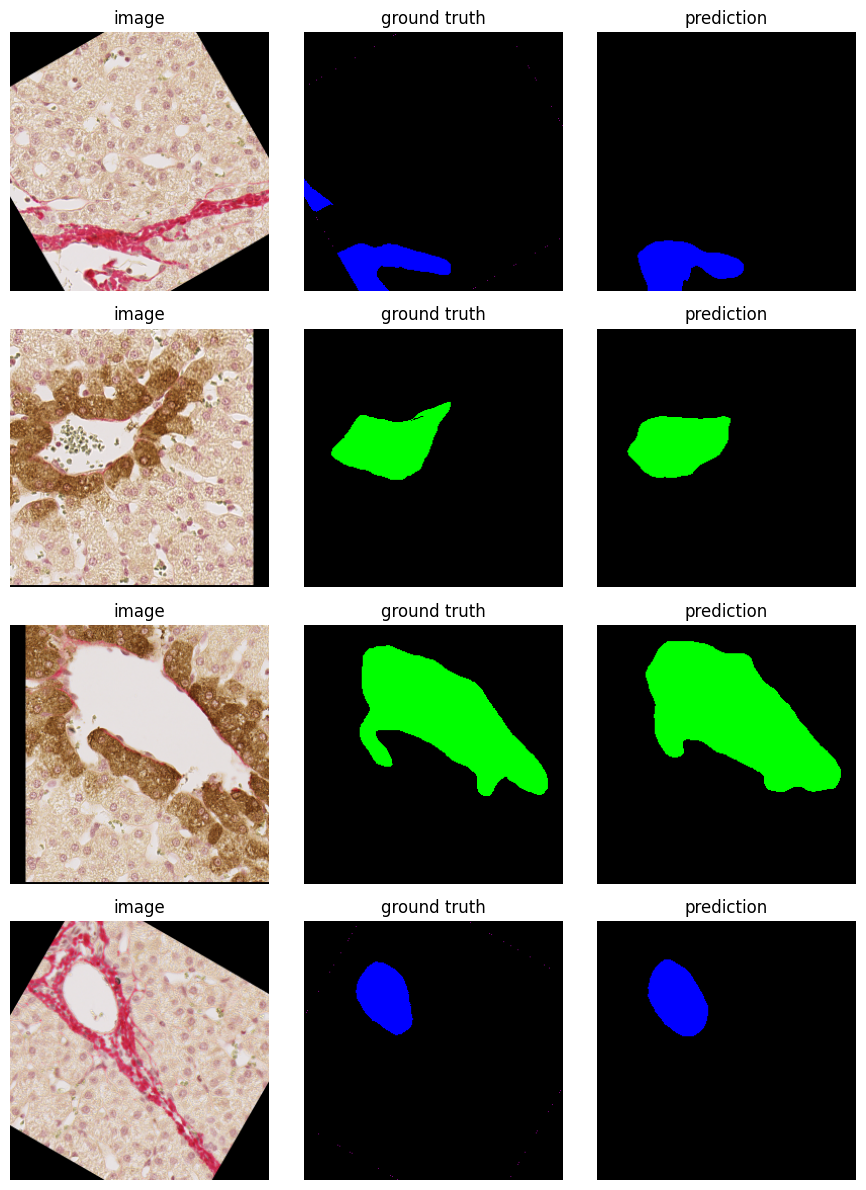

In [18]:
import matplotlib.pyplot as plt

def decode_class_map(class_map):
    return DISPLAY_COLORS[class_map]

n_show = 4
fig, axes = plt.subplots(n_show, 3, figsize=(9, 3 * n_show))

sample_idxs = np.random.choice(len(test_ds), size=n_show, replace=False)
with torch.no_grad():
    for row, idx in enumerate(sample_idxs):
        img_path, _ = test_pairs[idx]
        raw_img = cv2.cvtColor(cv2.imread(img_path, cv2.IMREAD_COLOR), cv2.COLOR_BGR2RGB)
        raw_img = cv2.resize(raw_img, (PATCH_SIZE, PATCH_SIZE), interpolation=cv2.INTER_AREA)

        image_t, mask_t = test_ds[idx]
        logits = model(image_t.unsqueeze(0).to(device))
        pred = torch.argmax(logits, dim=1).squeeze(0).cpu().numpy()

        axes[row, 0].imshow(raw_img); axes[row, 0].set_title("image"); axes[row, 0].axis("off")
        axes[row, 1].imshow(decode_class_map(mask_t.numpy())); axes[row, 1].set_title("ground truth"); axes[row, 1].axis("off")
        axes[row, 2].imshow(decode_class_map(pred)); axes[row, 2].set_title("prediction"); axes[row, 2].axis("off")

plt.tight_layout()
plt.savefig("/kaggle/working/segformer_test_qualitative.png", dpi=120)
plt.show()


## Cell 13 — Save results + zip + download

In [13]:
os.makedirs("/kaggle/working/logs", exist_ok=True)
test_metrics_path = "/kaggle/working/logs/vessel_run7_segformer_test_metrics.csv"
confusion_path = "/kaggle/working/logs/vessel_run7_segformer_confusion_matrix.csv"

test_metrics_df.to_csv(test_metrics_path, index=False)
confusion_df.to_csv(confusion_path)

print(f"Saved: {test_metrics_path}")
print(f"Saved: {confusion_path}")

!zip -r /kaggle/working/vessel_run7_test_results.zip /kaggle/working/logs/vessel_run7_segformer_test_metrics.csv /kaggle/working/logs/vessel_run7_segformer_confusion_matrix.csv /kaggle/working/segformer_test_qualitative.png


Saved: /kaggle/working/logs/vessel_run7_segformer_test_metrics.csv
Saved: /kaggle/working/logs/vessel_run7_segformer_confusion_matrix.csv
  adding: kaggle/working/logs/vessel_run7_segformer_test_metrics.csv (deflated 41%)
  adding: kaggle/working/logs/vessel_run7_segformer_confusion_matrix.csv (deflated 35%)
  adding: kaggle/working/segformer_test_qualitative.png (deflated 1%)
